In [2]:

import pandas as pd
from pathlib import Path

# Load the dataset from a local upload in Google Colab.
from google.colab import files

uploaded = files.upload()

csv_files = [
    filename
    for filename in uploaded
    if filename.lower().endswith(".csv")
]

if len(csv_files) != 1:
    raise ValueError(
        f"Expected exactly one CSV file, but found {len(csv_files)}. "
        "Upload the Mall Customer dataset CSV only."
    )

df = pd.read_csv(csv_files[0])

print("=" * 60)
print("CUSTOMER SEGMENTATION AI — DATA AUDIT")
print("=" * 60)

print(f"\nDataset file: {csv_files[0]}")
print(f"Dataset shape: {df.shape}")

print("\n--- First 5 Rows ---")
display(df.head())

print("\n--- Column Names ---")
print(df.columns.tolist())

print("\n--- Data Types ---")
print(df.dtypes)

print("\n--- Missing Values ---")
display(
    df.isnull()
    .sum()
    .rename("missing_count")
    .to_frame()
)

print("\n--- Duplicate Rows ---")
print(f"Duplicate count: {df.duplicated().sum()}")

print("\n--- Statistical Summary ---")
display(df.describe(include="all").T)

print("\n--- Unique Values Per Column ---")
display(
    df.nunique()
    .rename("unique_values")
    .to_frame()
)

print("\n--- Data Audit Completed ---")


Saving Mall_Customers.csv to Mall_Customers.csv
CUSTOMER SEGMENTATION AI — DATA AUDIT

Dataset file: Mall_Customers.csv
Dataset shape: (200, 5)

--- First 5 Rows ---


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40



--- Column Names ---
['CustomerID', 'Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']

--- Data Types ---
CustomerID                 int64
Gender                    object
Age                        int64
Annual Income (k$)         int64
Spending Score (1-100)     int64
dtype: object

--- Missing Values ---


,missing_count
CustomerID,0
Gender,0
Age,0
Annual Income (k$),0
Spending Score (1-100),0



--- Duplicate Rows ---
Duplicate count: 0

--- Statistical Summary ---


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
CustomerID,200.0,NaN,NaN,NaN,100.5,57.879185,1.0,50.75,100.5,150.25,200.0
Gender,200,2,Female,112,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,200.0,NaN,NaN,NaN,38.85,13.969007,18.0,28.75,36.0,49.0,70.0
Annual Income (k$),200.0,NaN,NaN,NaN,60.56,26.264721,15.0,41.5,61.5,78.0,137.0
Spending Score (1-100),200.0,NaN,NaN,NaN,50.2,25.823522,1.0,34.75,50.0,73.0,99.0



--- Unique Values Per Column ---


,unique_values
CustomerID,200
Gender,2
Age,51
Annual Income (k$),64
Spending Score (1-100),84



--- Data Audit Completed ---


Selected Features:
   Annual Income (k$)  Spending Score (1-100)
0                  15                      39
1                  15                      81
2                  16                       6
3                  16                      77
4                  17                      40

Feature Summary:


,count,mean,std,min,25%,50%,75%,max
Annual Income (k$),200.0,60.56,26.264721,15.0,41.50,61.5,78.0,137.0
Spending Score (1-100),200.0,50.20,25.823522,1.0,34.75,50.0,73.0,99.0


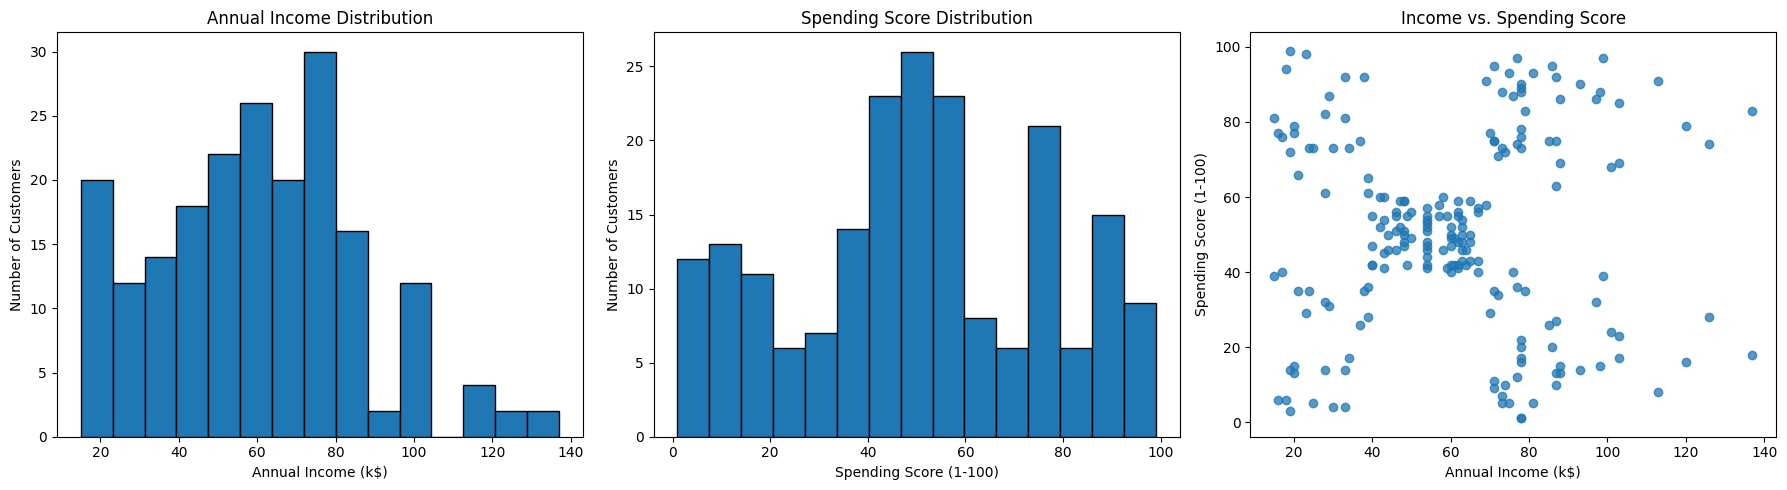


Feature Correlation:


,Annual Income (k$),Spending Score (1-100)
Annual Income (k$),1.00,0.01
Spending Score (1-100),0.01,1.00


In [3]:

import matplotlib.pyplot as plt
import pandas as pd

# Select the business features used in the segmentation task.
features = [
    "Annual Income (k$)",
    "Spending Score (1-100)"
]

X = df[features].copy()

# Validate the selected features before visualization.
if X.isnull().any().any():
    raise ValueError("Missing values detected in the selected features.")

if not all(pd.api.types.is_numeric_dtype(X[col]) for col in features):
    raise TypeError("All selected features must be numeric.")

print("Selected Features:")
print(X.head())

print("\nFeature Summary:")
display(X.describe().T)

# Create a visual overview of the feature distributions and relationship.
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].hist(X["Annual Income (k$)"], bins=15, edgecolor="black")
axes[0].set_title("Annual Income Distribution")
axes[0].set_xlabel("Annual Income (k$)")
axes[0].set_ylabel("Number of Customers")

axes[1].hist(
    X["Spending Score (1-100)"],
    bins=15,
    edgecolor="black"
)
axes[1].set_title("Spending Score Distribution")
axes[1].set_xlabel("Spending Score (1-100)")
axes[1].set_ylabel("Number of Customers")

axes[2].scatter(
    X["Annual Income (k$)"],
    X["Spending Score (1-100)"],
    alpha=0.75
)
axes[2].set_title("Income vs. Spending Score")
axes[2].set_xlabel("Annual Income (k$)")
axes[2].set_ylabel("Spending Score (1-100)")

plt.tight_layout()
plt.show()

# Inspect the relationship between the two features.
print("\nFeature Correlation:")
display(X.corr().round(3))


K-Means Evaluation Results:


,k,inertia,silhouette_score
0,2,269.6910,0.3213
1,3,157.7040,0.4666
2,4,108.9213,0.4939
3,5,65.5684,0.5547
4,6,55.0573,0.5399
5,7,44.8648,0.5281
6,8,37.2282,0.4552
7,9,32.3923,0.4571
8,10,29.9819,0.4432


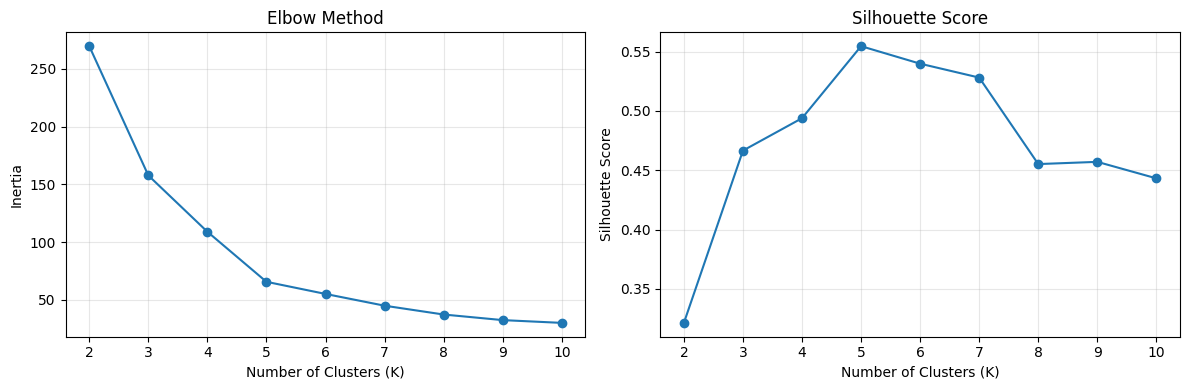

Highest Silhouette Score: K = 5
Note: We will select the final K after reviewing both the metrics and the cluster interpretability.


In [4]:

import matplotlib.pyplot as plt
import pandas as pd

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

# Scale the selected features before applying distance-based clustering.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

results = []

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled)

    results.append({
        "k": k,
        "inertia": kmeans.inertia_,
        "silhouette_score": silhouette_score(X_scaled, labels)
    })

results_df = pd.DataFrame(results)

print("K-Means Evaluation Results:")
display(results_df.round(4))

# Compare the Elbow Method and Silhouette Score.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(
    results_df["k"],
    results_df["inertia"],
    marker="o"
)
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of Clusters (K)")
axes[0].set_ylabel("Inertia")
axes[0].set_xticks(results_df["k"])
axes[0].grid(alpha=0.3)

axes[1].plot(
    results_df["k"],
    results_df["silhouette_score"],
    marker="o"
)
axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("Number of Clusters (K)")
axes[1].set_ylabel("Silhouette Score")
axes[1].set_xticks(results_df["k"])
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

best_silhouette_k = int(
    results_df.loc[
        results_df["silhouette_score"].idxmax(), "k"
    ]
)

print(f"Highest Silhouette Score: K = {best_silhouette_k}")
print(
    "Note: We will select the final K after reviewing both "
    "the metrics and the cluster interpretability."
)


Cluster Sizes:


,Customer Count
Cluster,
0,81
1,39
2,22
3,35
4,23



Cluster Profiles:


,Customer_Count,Mean_Annual_Income,Median_Annual_Income,Mean_Spending_Score,Median_Spending_Score
Cluster,,,,,
0,81,55.30,54.0,49.52,50.0
1,39,86.54,79.0,82.13,83.0
2,22,25.73,24.5,79.36,77.0
3,35,88.20,85.0,17.11,16.0
4,23,26.30,25.0,20.91,17.0



Cluster Centers (Original Scale):


,Annual Income (k$),Spending Score (1-100)
Cluster,,
0,55.30,49.52
1,86.54,82.13
2,25.73,79.36
3,88.20,17.11
4,26.30,20.91


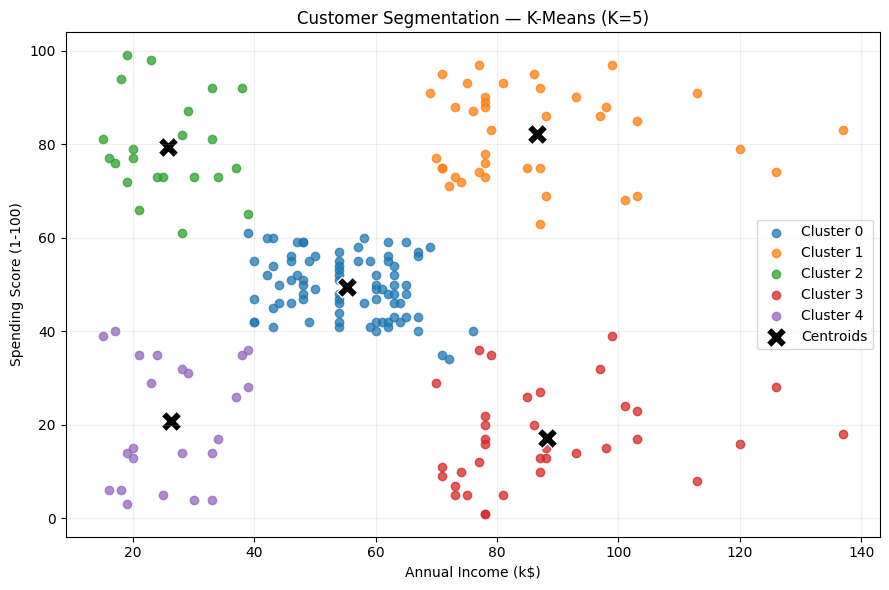

In [5]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans

# Train the candidate final model using the selected K.
FINAL_K = 5

kmeans_model = KMeans(
    n_clusters=FINAL_K,
    random_state=42,
    n_init=10
)

cluster_labels = kmeans_model.fit_predict(X_scaled)

# Keep the original feature values for business interpretation.
segmented_df = X.copy()
segmented_df["Cluster"] = cluster_labels

# Convert cluster centers back to the original feature scale.
centers = scaler.inverse_transform(kmeans_model.cluster_centers_)

centers_df = pd.DataFrame(
    centers,
    columns=features
)
centers_df.index.name = "Cluster"

print("Cluster Sizes:")
display(
    segmented_df["Cluster"]
    .value_counts()
    .sort_index()
    .rename("Customer Count")
    .to_frame()
)

print("\nCluster Profiles:")
cluster_profiles = segmented_df.groupby("Cluster").agg(
    Customer_Count=("Cluster", "size"),
    Mean_Annual_Income=("Annual Income (k$)", "mean"),
    Median_Annual_Income=("Annual Income (k$)", "median"),
    Mean_Spending_Score=("Spending Score (1-100)", "mean"),
    Median_Spending_Score=("Spending Score (1-100)", "median")
).round(2)

display(cluster_profiles)

print("\nCluster Centers (Original Scale):")
display(centers_df.round(2))

# Visualize customers and their cluster centers.
plt.figure(figsize=(9, 6))

for cluster_id in sorted(segmented_df["Cluster"].unique()):
    cluster_data = segmented_df[
        segmented_df["Cluster"] == cluster_id
    ]

    plt.scatter(
        cluster_data["Annual Income (k$)"],
        cluster_data["Spending Score (1-100)"],
        label=f"Cluster {cluster_id}",
        alpha=0.75
    )

plt.scatter(
    centers[:, 0],
    centers[:, 1],
    marker="X",
    s=220,
    c="black",
    edgecolors="white",
    linewidths=1,
    label="Centroids"
)

plt.title("Customer Segmentation — K-Means (K=5)")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


In [6]:

from sklearn.metrics import silhouette_score

# Business-oriented labels based on the observed cluster profiles.
cluster_names = {
    0: "Average Income - Average Spending",
    1: "High Income - High Spending",
    2: "Low Income - High Spending",
    3: "High Income - Low Spending",
    4: "Low Income - Low Spending"
}

segmented_df["Segment"] = segmented_df["Cluster"].map(cluster_names)

# Summarize the segments for business interpretation.
segment_summary = segmented_df.groupby(
    ["Cluster", "Segment"],
    as_index=False
).agg(
    Customer_Count=("Annual Income (k$)", "size"),
    Average_Income=("Annual Income (k$)", "mean"),
    Average_Spending=("Spending Score (1-100)", "mean")
).round(2)

segment_summary["Customer_Percentage"] = (
    segment_summary["Customer_Count"] / len(segmented_df) * 100
).round(2)

print("Final Segment Summary:")
display(segment_summary)

# Evaluate the final clustering on the scaled feature space.
final_silhouette = silhouette_score(X_scaled, segmented_df["Cluster"])

print(f"Final number of clusters: {FINAL_K}")
print(f"Final Silhouette Score: {final_silhouette:.4f}")
print(f"Total customers: {len(segmented_df)}")
print(f"Total assigned customers: {segmented_df['Cluster'].notna().sum()}")


Final Segment Summary:


,Cluster,Segment,Customer_Count,Average_Income,Average_Spending,Customer_Percentage
0,0,Average Income - Average Spending,81,55.30,49.52,40.5
1,1,High Income - High Spending,39,86.54,82.13,19.5
2,2,Low Income - High Spending,22,25.73,79.36,11.0
3,3,High Income - Low Spending,35,88.20,17.11,17.5
4,4,Low Income - Low Spending,23,26.30,20.91,11.5


Final number of clusters: 5
Final Silhouette Score: 0.5547
Total customers: 200
Total assigned customers: 200


In [7]:

import numpy as np
import pandas as pd

from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score

dbscan_results = []

# Test a small, documented parameter grid on the scaled features.
for eps in [0.2, 0.3, 0.4, 0.5, 0.6]:
    for min_samples in [3, 5]:
        model = DBSCAN(
            eps=eps,
            min_samples=min_samples
        )

        labels = model.fit_predict(X_scaled)

        n_noise = int(np.sum(labels == -1))
        n_clusters = len(set(labels) - {-1})
        non_noise_mask = labels != -1

        score = np.nan

        # Silhouette requires at least two clusters among evaluated samples.
        if (
            n_clusters >= 2
            and non_noise_mask.sum() > n_clusters
        ):
            score = silhouette_score(
                X_scaled[non_noise_mask],
                labels[non_noise_mask]
            )

        dbscan_results.append({
            "eps": eps,
            "min_samples": min_samples,
            "n_clusters": n_clusters,
            "noise_count": n_noise,
            "noise_percentage": round(
                n_noise / len(labels) * 100, 2
            ),
            "silhouette_non_noise": score
        })

dbscan_df = pd.DataFrame(dbscan_results)

print("DBSCAN Parameter Comparison:")
display(dbscan_df.round(4))

print("\nK-Means Reference:")
print(f"Clusters: {FINAL_K}")
print(f"Silhouette Score: {final_silhouette:.4f}")


DBSCAN Parameter Comparison:


,eps,min_samples,n_clusters,noise_count,noise_percentage,silhouette_non_noise
0,0.2,3,13,44,22.0,0.4697
1,0.2,5,7,77,38.5,0.5856
2,0.3,3,9,14,7.0,0.4720
3,0.3,5,7,35,17.5,0.5243
4,0.4,3,4,10,5.0,0.3954
5,0.4,5,4,15,7.5,0.4781
6,0.5,3,2,7,3.5,0.3892
7,0.5,5,2,8,4.0,0.3876
8,0.6,3,1,0,0.0,NaN
9,0.6,5,1,5,2.5,NaN



K-Means Reference:
Clusters: 5
Silhouette Score: 0.5547


In [8]:

import joblib
import numpy as np
import pandas as pd

from pathlib import Path
from sklearn.cluster import KMeans
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

# Refit the complete preprocessing and clustering pipeline.
final_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("kmeans", KMeans(
        n_clusters=5,
        random_state=42,
        n_init=10
    ))
])

final_labels = final_pipeline.fit_predict(X[features])

# Validate predictions and cluster coverage.
if len(final_labels) != len(X):
    raise RuntimeError("Prediction count does not match dataset size.")

if set(np.unique(final_labels)) != set(range(5)):
    raise RuntimeError("Expected exactly five clusters: 0 through 4.")

if not np.isfinite(final_pipeline.named_steps["kmeans"].cluster_centers_).all():
    raise RuntimeError("Non-finite cluster centers detected.")

validated_silhouette = silhouette_score(
    final_pipeline.named_steps["scaler"].transform(X[features]),
    final_labels
)

# Build cluster profiles from the newly fitted pipeline.
validation_df = X[features].copy()
validation_df["Cluster"] = final_labels

validated_profiles = validation_df.groupby("Cluster").agg(
    Customer_Count=("Annual Income (k$)", "size"),
    Mean_Annual_Income=("Annual Income (k$)", "mean"),
    Mean_Spending_Score=("Spending Score (1-100)", "mean")
).round(2)

# Store the feature order and labels for consistent inference.
artifact = {
    "pipeline": final_pipeline,
    "features": features,
    "cluster_names": cluster_names,
    "cluster_profiles": validated_profiles,
    "n_clusters": 5,
    "silhouette_score": float(validated_silhouette),
    "random_state": 42
}

output_dir = Path("/content/customer_segmentation_artifacts")
output_dir.mkdir(parents=True, exist_ok=True)

artifact_path = output_dir / "customer_segmentation_model.joblib"
joblib.dump(artifact, artifact_path)

# Reload and verify the saved artifact in the current runtime.
loaded_artifact = joblib.load(artifact_path)

reloaded_labels = loaded_artifact["pipeline"].predict(X[features])

if not np.array_equal(final_labels, reloaded_labels):
    raise RuntimeError("Reloaded artifact predictions do not match.")

print("Validation: PASSED")
print(f"Customers validated: {len(X)}")
print(f"Clusters: {loaded_artifact['n_clusters']}")
print(f"Silhouette Score: {validated_silhouette:.4f}")
print(f"Saved artifact: {artifact_path}")
print(f"Artifact size: {artifact_path.stat().st_size:,} bytes")
print("\nValidated Cluster Profiles:")
display(validated_profiles)


Validation: PASSED
Customers validated: 200
Clusters: 5
Silhouette Score: 0.5547
Saved artifact: /content/customer_segmentation_artifacts/customer_segmentation_model.joblib
Artifact size: 3,757 bytes

Validated Cluster Profiles:


,Customer_Count,Mean_Annual_Income,Mean_Spending_Score
Cluster,,,
0,81,55.30,49.52
1,39,86.54,82.13
2,22,25.73,79.36
3,35,88.20,17.11
4,23,26.30,20.91


In [9]:

from google.colab import files

artifact_path = (
    "/content/customer_segmentation_artifacts/"
    "customer_segmentation_model.joblib"
)

files.download(artifact_path)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>